In [37]:
import pandas as pd
import numpy as np
import torch
import torch
import torch.nn as nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset,DataLoader
import torch.optim as optim

In [7]:
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [66]:
x=data.drop('target',axis=1)
y=data['target']

In [67]:
x=x.to_numpy()
y=y.to_numpy()

In [68]:
x.shape,y.shape

((150, 4), (150,))

In [69]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [78]:
x_train_tensor=torch.tensor(x_train,dtype=torch.float)
x_test_tensor=torch.tensor(x_test,dtype=torch.int)
y_train_tensor=torch.tensor(y_train,dtype=torch.float)
y_test_tensor=torch.tensor(y_test,dtype=torch.int)

In [79]:
train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
test_dataset=TensorDataset(x_test_tensor,y_test_tensor)

In [80]:
train_loader=DataLoader(train_dataset,shuffle=True)
test_loader=DataLoader(test_dataset,shuffle=False)

In [81]:
class IrisModel(nn.Module):
    def __init__(self,in_features,out_features):
        super().__init__()
        self.fc1=nn.Linear(in_features=in_features,out_features=32)
        self.fc2=nn.Linear(in_features=32,out_features=64)
        self.out=nn.Linear(in_features=64,out_features=3)
        self.relu=nn.ReLU()
        self.softmax=nn.Softmax()

    def forward(self,x):
        x=self.fc1(x)
        x=self.relu(x)
        x=self.fc2(x)
        x=self.relu(x)
        x=self.out(x)
        x=self.softmax(x)

        return x

In [82]:
lr=0.001
epochs=500

In [83]:
model=IrisModel(in_features=4,out_features=3)

In [84]:
optimizer=optim.Adam(model.parameters(),lr=lr)
loss_fn=nn.CrossEntropyLoss()

In [100]:
train_losses=[]
test_losses=[]

for epoch in range(epochs):
    running_loss=0.0
    running_test_loss=0.0
    model.train()
    for x_batch,y_batch in train_loader:
        y_batch = y_batch.view(-1).long()
        model.zero_grad()
        pred=model(x_batch)
        loss=loss_fn(pred,y_batch)
        running_loss+=loss.item()
        loss.backward()
        optimizer.step()
    train_losses.append(running_loss/len(train_loader))
    model.eval()

    with torch.no_grad():
        for x_batch,y_batch in test_loader:
            x_batch = x_batch.float()
            y_batch=y_batch.view(-1).long()
            pred=model(x_batch)
            loss=loss_fn(pred,y_batch)
            running_test_loss += loss.item()
        test_losses.append(
            running_test_loss / len(test_loader)
        )
        if epoch % 100==0:
            print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Train Loss: {train_losses[-1]:.4f}, "
            f"Test Loss: {test_losses[-1]:.4f}"
        )

Epoch 1/500, Train Loss: 0.8348, Test Loss: 0.8181
Epoch 101/500, Train Loss: 0.5681, Test Loss: 0.5848
Epoch 201/500, Train Loss: 0.5681, Test Loss: 0.5848
Epoch 301/500, Train Loss: 0.5681, Test Loss: 0.5848
Epoch 401/500, Train Loss: 0.5681, Test Loss: 0.5848


In [91]:
import matplotlib.pyplot as plt


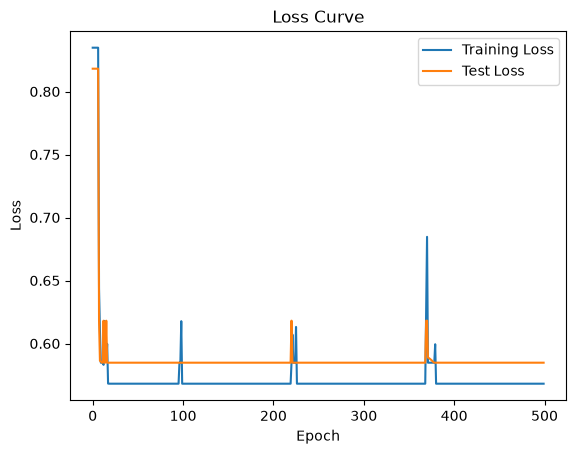

In [101]:
plt.plot(train_losses,label="Training Loss")
plt.plot(test_losses,label="Test Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()